# Travel Reimbursement Approval Agent

A runnable GenAI / agentic prototype that reviews employee travel-reimbursement claims against a written policy,
receipts, per-diem limits and approval rules, and returns a structured recommendation:
`APPROVE`, `PARTIAL_APPROVE`, `REJECT` or `MANUAL_REVIEW`.

## README

**What this notebook contains (top to bottom):** configuration + embedded data -> models -> policy grounding ->
tools -> decision engine -> validator -> agent -> run on the 5 provided claims -> sample outputs ->
**Dashboard** (charts + interactive UI) -> **Evaluation & tests** -> **Design Notes & Reasoning** -> final JSON.

### Setup
1. Python **3.10+**.
2. Install dependencies (once):
   ```bash
   pip install openai pandas matplotlib pydantic python-dotenv ipywidgets jupyter
   ```
3. *(Optional, for LLM mode)* create a `.env` file next to this notebook:
   ```
   OPENAI_API_KEY=sk-...
   OPENAI_MODEL=gpt-4o-mini        # any OpenAI chat model with function calling
   OPENAI_BASE_URL=                # leave empty for OpenAI; or any OpenAI-compatible endpoint (e.g. local Ollama)
   ```
4. **Run all cells** (`Kernel -> Restart & Run All`). No manual steps are needed.

### Environment variables
| Variable | Required | Default | Purpose |
|---|---|---|---|
| `OPENAI_API_KEY` | No | - | Enables **LLM mode**. Without it the agent runs in **offline mode** (same tools, deterministic planner). |
| `OPENAI_MODEL` | No | `gpt-4o-mini` | OpenAI chat model used in LLM mode. |
| `OPENAI_BASE_URL` | No | OpenAI default | Optional OpenAI-compatible endpoint. Use the base URL only (e.g. `https://api.openai.com/v1`). |
| `MAX_AGENT_TURNS` | No | `12` | Safety cap on tool-calling turns per claim. |

> The outputs saved in this notebook were produced in **offline mode** (no API key). With a key set, the same
> notebook runs the OpenAI tool-calling agent; every LLM decision is still cross-checked by the policy engine.

### How it works
```
claim (JSON/CSV/UI) -> intake -> Agent
  LLM mode : OpenAI model <-> tools (lookup_policy, check_claim_consistency, check_category_eligibility,
             check_receipts, check_per_diem_limits, check_timeliness, check_approval_threshold)
             -> submit_decision(decision, confidence, explanation)
  Offline  : same tools, fixed order
      -> policy-engine cross-check (disagreement => MANUAL_REVIEW)
      -> output validator (invalid => MANUAL_REVIEW) -> structured result
```
Key design choices: tools do all arithmetic; the LLM chooses tools and explains; independent verification and
validation guard every result; uncertain cases go to Manual Review. Details in **Design Notes & Reasoning** below.

## 1. Configuration and embedded data
Policy rules, limits, approval matrix, the five provided claims (Appendix B), mock receipt metadata and the labelled evaluation cases are embedded so the notebook needs no other files.

In [1]:
import json, os, re, sys
from types import SimpleNamespace

try:  # optional: read OPENAI_* settings from a .env file next to the notebook
    from dotenv import find_dotenv, load_dotenv
    load_dotenv(find_dotenv(usecwd=True))
except ImportError:
    pass

config = SimpleNamespace(
    OPENAI_API_KEY=os.getenv("OPENAI_API_KEY"),
    OPENAI_MODEL=os.getenv("OPENAI_MODEL", "gpt-4o-mini"),
    OPENAI_BASE_URL=os.getenv("OPENAI_BASE_URL") or None,
    MAX_AGENT_TURNS=int(os.getenv("MAX_AGENT_TURNS", "12")),
)

In [2]:
EMBEDDED = json.loads(r'''
{
 "policy_rules": [
  {
   "id": "POL-CAT-01",
   "title": "Eligible categories",
   "text": "Reimbursable when incurred for a documented business purpose: airfare (economy class only, see POL-AIR-01), lodging (hotel room charges), meals (subject to per-diem limits, see POL-PD-01), ground transport (taxi, rideshare, train, rental car, parking), conference / registration fees.",
   "tags": [
    "eligible",
    "categories",
    "airfare",
    "lodging",
    "meals",
    "ground",
    "transport",
    "taxi",
    "rideshare",
    "train",
    "rental",
    "parking",
    "conference",
    "registration",
    "fees"
   ]
  },
  {
   "id": "POL-CAT-02",
   "title": "Ineligible items",
   "text": "Never reimbursable; rejected (deducted in full): alcohol and minibar charges; spa, gym, and personal entertainment; in-room movies, personal shopping, gifts; traffic fines, penalties, and late fees; any personal (non-business) expense.",
   "tags": [
    "ineligible",
    "spa",
    "minibar",
    "alcohol",
    "gym",
    "entertainment",
    "movies",
    "shopping",
    "gifts",
    "fines",
    "penalties",
    "personal",
    "reject",
    "deducted"
   ]
  },
  {
   "id": "POL-PD-01",
   "title": "Meals per-diem",
   "text": "Maximum $75 per day. Amounts above the daily cap are deducted; the rest is reimbursed.",
   "tags": [
    "meals",
    "per",
    "diem",
    "daily",
    "cap",
    "75",
    "dinner",
    "lunch",
    "breakfast",
    "food"
   ]
  },
  {
   "id": "POL-PD-02",
   "title": "Lodging nightly cap",
   "text": "Maximum $200 per night. Amounts above the nightly cap are deducted; the rest is reimbursed.",
   "tags": [
    "lodging",
    "hotel",
    "night",
    "nightly",
    "cap",
    "200",
    "room"
   ]
  },
  {
   "id": "POL-PD-03",
   "title": "Ground transport cap",
   "text": "Maximum $50 per day. Amounts above the cap are deducted.",
   "tags": [
    "ground",
    "transport",
    "taxi",
    "rideshare",
    "train",
    "rental",
    "parking",
    "daily",
    "cap",
    "50"
   ]
  },
  {
   "id": "POL-AIR-01",
   "title": "Airfare class",
   "text": "Only economy class airfare is reimbursable. Business/first-class fares are a policy exception and must be routed to Manual Review (not auto-deducted, because a pre-approval may exist).",
   "tags": [
    "airfare",
    "flight",
    "class",
    "economy",
    "business",
    "first",
    "exception",
    "manual",
    "review",
    "pre-approval"
   ]
  },
  {
   "id": "POL-RCT-01",
   "title": "Receipt required above $25",
   "text": "Any single line item greater than $25 requires an attached, itemized receipt. Airfare and lodging always require a receipt regardless of amount.",
   "tags": [
    "receipt",
    "itemized",
    "required",
    "25",
    "airfare",
    "lodging",
    "attachment"
   ]
  },
  {
   "id": "POL-RCT-02",
   "title": "Missing receipt handling",
   "text": "If a receipt is missing for an item that requires one, the item is not silently rejected - the claim is routed to Manual Review so the reviewer can request the receipt.",
   "tags": [
    "missing",
    "receipt",
    "manual",
    "review",
    "request"
   ]
  },
  {
   "id": "POL-APR-01",
   "title": "Auto-approve tier",
   "text": "Total <= $500: may be auto-approved by the agent if fully compliant.",
   "tags": [
    "approval",
    "threshold",
    "auto",
    "approve",
    "tier",
    "500",
    "total"
   ]
  },
  {
   "id": "POL-APR-02",
   "title": "Manager tier",
   "text": "Total > $500 and <= $2,000: eligible for approval, treated as approvable when fully compliant.",
   "tags": [
    "approval",
    "threshold",
    "manager",
    "tier",
    "500",
    "2000",
    "total"
   ]
  },
  {
   "id": "POL-APR-03",
   "title": "Director / Manual-Review tier",
   "text": "Total > $2,000: exceeds the agent's auto-approval authority and must be routed to Manual Review (director approval required), even if otherwise compliant.",
   "tags": [
    "approval",
    "threshold",
    "director",
    "manual",
    "review",
    "2000",
    "high",
    "value",
    "total"
   ]
  },
  {
   "id": "POL-TIME-01",
   "title": "Submission window",
   "text": "Claims must be submitted within 30 days of the expense date. Late claims are routed to Manual Review.",
   "tags": [
    "timeliness",
    "submission",
    "window",
    "30",
    "days",
    "late",
    "deadline"
   ]
  }
 ],
 "limits": {
  "currency": "USD",
  "per_diem": {
   "meals": {
    "cap": 75,
    "unit": "day",
    "rule": "POL-PD-01"
   },
   "lodging": {
    "cap": 200,
    "unit": "night",
    "rule": "POL-PD-02"
   },
   "ground_transport": {
    "cap": 50,
    "unit": "day",
    "rule": "POL-PD-03"
   }
  },
  "receipt": {
   "required_above": 25,
   "always_required": [
    "airfare",
    "lodging"
   ]
  },
  "submission_window_days": 30,
  "categories": {
   "eligible": [
    "airfare",
    "lodging",
    "meals",
    "ground_transport",
    "conference_fees"
   ],
   "ineligible": [
    "alcohol",
    "minibar",
    "spa",
    "gym",
    "entertainment",
    "movies",
    "shopping",
    "gifts",
    "fines",
    "personal"
   ]
  },
  "aliases": {
   "flight": "airfare",
   "hotel": "lodging",
   "meal": "meals",
   "food": "meals",
   "taxi": "ground_transport",
   "rideshare": "ground_transport",
   "train": "ground_transport",
   "rental_car": "ground_transport",
   "parking": "ground_transport",
   "ground": "ground_transport",
   "conference": "conference_fees",
   "registration": "conference_fees",
   "conference_registration": "conference_fees",
   "fine": "fines",
   "gift": "gifts",
   "movie": "movies",
   "personal_expense": "personal"
  }
 },
 "approval_matrix": {
  "tiers": [
   {
    "id": "POL-APR-01",
    "name": "Auto-approve",
    "max": 500,
    "action": "AUTO_APPROVE"
   },
   {
    "id": "POL-APR-02",
    "name": "Manager",
    "max": 2000,
    "action": "APPROVABLE"
   },
   {
    "id": "POL-APR-03",
    "name": "Director",
    "max": null,
    "action": "MANUAL_REVIEW"
   }
  ]
 },
 "claims": [
  {
   "claim_id": "CLM-001",
   "employee": "A. Rivera",
   "purpose": "Attend 2-day industry conference (business)",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-12",
   "submitted_date": "2026-06-20",
   "currency": "USD",
   "total_claimed": 1110.0,
   "items": [
    {
     "category": "airfare",
     "description": "Round-trip economy airfare",
     "amount": 420.0,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1,
     "fare_class": "economy"
    },
    {
     "category": "lodging",
     "description": "Hotel, 2 nights @ $180",
     "amount": 360.0,
     "receipt_attached": true,
     "units": 2,
     "attendees": 1
    },
    {
     "category": "meals",
     "description": "Meals, 3 days @ ~$60/day",
     "amount": 180.0,
     "receipt_attached": true,
     "units": 3,
     "attendees": 1
    },
    {
     "category": "conference_fees",
     "description": "Conference registration",
     "amount": 150.0,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1
    }
   ]
  },
  {
   "claim_id": "CLM-002",
   "employee": "B. Osei",
   "purpose": "Weekend hotel stay",
   "trip_start": "2026-06-14",
   "trip_end": "2026-06-15",
   "submitted_date": "2026-06-25",
   "currency": "USD",
   "total_claimed": 380.0,
   "items": [
    {
     "category": "spa",
     "description": "Hotel spa package",
     "amount": 300.0,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1
    },
    {
     "category": "minibar",
     "description": "In-room minibar",
     "amount": 80.0,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1
    }
   ]
  },
  {
   "claim_id": "CLM-003",
   "employee": "C. Nakamura",
   "purpose": "Client site visit (business)",
   "trip_start": "2026-06-08",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-06-22",
   "currency": "USD",
   "total_claimed": 940.0,
   "items": [
    {
     "category": "airfare",
     "description": "Round-trip economy airfare",
     "amount": 300.0,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1,
     "fare_class": "economy"
    },
    {
     "category": "lodging",
     "description": "Hotel, 2 nights @ $250",
     "amount": 500.0,
     "receipt_attached": true,
     "units": 2,
     "attendees": 1
    },
    {
     "category": "meals",
     "description": "Meals, 2 days @ $70/day",
     "amount": 140.0,
     "receipt_attached": true,
     "units": 2,
     "attendees": 1
    }
   ]
  },
  {
   "claim_id": "CLM-004",
   "employee": "D. Fischer",
   "purpose": "International vendor negotiation (business)",
   "trip_start": "2026-06-16",
   "trip_end": "2026-06-18",
   "submitted_date": "2026-06-28",
   "currency": "USD",
   "total_claimed": 3000.0,
   "items": [
    {
     "category": "airfare",
     "description": "Business-class international airfare",
     "amount": 2400.0,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1,
     "fare_class": "business"
    },
    {
     "category": "lodging",
     "description": "Hotel, 3 nights",
     "amount": 600.0,
     "receipt_attached": false,
     "units": 3,
     "attendees": 1
    }
   ]
  },
  {
   "claim_id": "CLM-005",
   "employee": "E. Haddad",
   "purpose": "Client dinner / business development",
   "trip_start": "2026-06-11",
   "trip_end": "2026-06-11",
   "submitted_date": "2026-06-24",
   "currency": "USD",
   "total_claimed": 220.0,
   "items": [
    {
     "category": "meals",
     "description": "Client dinner for 4 (business development)",
     "amount": 220.0,
     "receipt_attached": false,
     "units": 1,
     "attendees": 4
    }
   ]
  }
 ],
 "receipts": {
  "CLM-001": [
   {
    "receipt_id": "R-CLM-001-01",
    "vendor": "SkyHigh Airlines (mock)",
    "date": "2026-06-10",
    "category": "airfare",
    "amount": 420.0,
    "itemized": true,
    "attachment": "receipts/CLM-001/airfare_receipt.txt"
   },
   {
    "receipt_id": "R-CLM-001-02",
    "vendor": "Grand Plaza Hotel (mock)",
    "date": "2026-06-12",
    "category": "lodging",
    "amount": 360.0,
    "itemized": true,
    "attachment": "receipts/CLM-001/lodging_receipt.txt"
   },
   {
    "receipt_id": "R-CLM-001-03",
    "vendor": "Bistro Central (mock)",
    "date": "2026-06-10",
    "category": "meals",
    "amount": 180.0,
    "itemized": true,
    "attachment": "receipts/CLM-001/meals_receipt.txt"
   },
   {
    "receipt_id": "R-CLM-001-04",
    "vendor": "TechConnect Summit (mock)",
    "date": "2026-06-10",
    "category": "conference_fees",
    "amount": 150.0,
    "itemized": true,
    "attachment": "receipts/CLM-001/conference_fees_receipt.txt"
   }
  ],
  "CLM-002": [
   {
    "receipt_id": "R-CLM-002-01",
    "vendor": "Serenity Spa at Grand Plaza (mock)",
    "date": "2026-06-15",
    "category": "spa",
    "amount": 300.0,
    "itemized": true,
    "attachment": "receipts/CLM-002/spa_receipt.txt"
   },
   {
    "receipt_id": "R-CLM-002-02",
    "vendor": "Grand Plaza Hotel - Minibar (mock)",
    "date": "2026-06-15",
    "category": "minibar",
    "amount": 80.0,
    "itemized": true,
    "attachment": "receipts/CLM-002/minibar_receipt.txt"
   }
  ],
  "CLM-003": [
   {
    "receipt_id": "R-CLM-003-01",
    "vendor": "SkyHigh Airlines (mock)",
    "date": "2026-06-08",
    "category": "airfare",
    "amount": 300.0,
    "itemized": true,
    "attachment": "receipts/CLM-003/airfare_receipt.txt"
   },
   {
    "receipt_id": "R-CLM-003-02",
    "vendor": "Grand Plaza Hotel (mock)",
    "date": "2026-06-10",
    "category": "lodging",
    "amount": 500.0,
    "itemized": true,
    "attachment": "receipts/CLM-003/lodging_receipt.txt"
   },
   {
    "receipt_id": "R-CLM-003-03",
    "vendor": "Bistro Central (mock)",
    "date": "2026-06-08",
    "category": "meals",
    "amount": 140.0,
    "itemized": true,
    "attachment": "receipts/CLM-003/meals_receipt.txt"
   }
  ],
  "CLM-004": [
   {
    "receipt_id": "R-CLM-004-01",
    "vendor": "SkyHigh Airlines (mock)",
    "date": "2026-06-16",
    "category": "airfare",
    "amount": 2400.0,
    "itemized": true,
    "attachment": "receipts/CLM-004/airfare_receipt.txt"
   }
  ],
  "CLM-005": []
 }
}
''')
print({k: len(v) for k, v in EMBEDDED.items()})

{'policy_rules': 12, 'limits': 6, 'approval_matrix': 1, 'claims': 5, 'receipts': 5}


### Policy used (Appendix A)

> Mock policy for this assignment. No real company or employee data. Every rule has a stable id (POL-*).

#### 1. Eligible & Ineligible Categories
**POL-CAT-01 - Eligible categories** - Reimbursable when incurred for a documented business purpose:
- Airfare (economy class only - see POL-AIR-01)
- Lodging (hotel room charges)
- Meals (subject to per-diem limits - see POL-PD-01)
- Ground transport (taxi, rideshare, train, rental car, parking)
- Conference / registration fees

**POL-CAT-02 - Ineligible items** - Never reimbursable; rejected (deducted in full):
- Alcohol and minibar charges
- Spa, gym, and personal entertainment
- In-room movies, personal shopping, gifts
- Traffic fines, penalties, and late fees
- Any personal (non-business) expense

#### 2. Per-Diem & Category Limits
- **POL-PD-01 - Meals** - Maximum $75 per day. Amounts above the daily cap are deducted; the rest is reimbursed.
- **POL-PD-02 - Lodging** - Maximum $200 per night. Amounts above the nightly cap are deducted; the rest is reimbursed.
- **POL-PD-03 - Ground transport** - Maximum $50 per day. Amounts above the cap are deducted.
- **POL-AIR-01 - Airfare class** - Only economy class airfare is reimbursable. Business/first-class fares are a policy exception and must be routed to Manual Review (not auto-deducted, because a pre-approval may exist).

#### 3. Receipt Rules
- **POL-RCT-01 - Receipt required above $25** - Any single line item greater than $25 requires an attached, itemized receipt. Airfare and lodging always require a receipt regardless of amount.
- **POL-RCT-02 - Missing receipt handling** - If a receipt is missing for an item that requires one, the item is not silently rejected - the claim is routed to Manual Review so the reviewer can request the receipt.

#### 4. Approval Thresholds
Thresholds are evaluated on the total reimbursable amount (after per-diem deductions but before final decision).
- **POL-APR-01 - Auto-approve tier** - Total <= $500: may be auto-approved by the agent if fully compliant.
- **POL-APR-02 - Manager tier** - Total > $500 and <= $2,000: eligible for approval, treated as approvable when fully compliant.
- **POL-APR-03 - Director / Manual-Review tier** - Total > $2,000: exceeds the agent's auto-approval authority and must be routed to Manual Review (director approval required), even if otherwise compliant.

#### 5. Timeliness
- **POL-TIME-01 - Submission window** - Claims must be submitted within 30 days of the expense date. Late claims are routed to Manual Review.

#### Decision Guidance (how the rules combine)
- **Approve** - every item eligible, all receipts present, all within per-diem, total within an approvable tier (POL-APR-01 / POL-APR-02).
- **Partially Approve** - the claim is valid but some amounts exceed per-diem caps; reimburse up to the cap and deduct the excess.
- **Reject** - the claimed items are ineligible (POL-CAT-02) with nothing reimbursable.
- **Manual Review** - any ambiguity, policy exception, high value (POL-APR-03), missing required receipt (POL-RCT-02), or conflicting information. Prefer Manual Review over forcing a decision.

## 2. Claim models and intake
Pydantic models define a claim and the **exact output contract**. Intake accepts JSON (object/array) or CSV.

In [3]:
from datetime import date
from typing import Literal, Optional

from pydantic import BaseModel, ConfigDict, Field

Decision = Literal["APPROVE", "PARTIAL_APPROVE", "REJECT", "MANUAL_REVIEW"]
DECISIONS = ["APPROVE", "PARTIAL_APPROVE", "REJECT", "MANUAL_REVIEW"]


class ClaimItem(BaseModel):
    category: str
    description: str
    amount: float = Field(gt=0)
    receipt_attached: bool
    units: int = Field(default=1, ge=1)      # days (meals/ground) or nights (lodging)
    attendees: int = Field(default=1, ge=1)  # people covered by a meal
    fare_class: Optional[str] = None         # airfare only
    expense_date: Optional[date] = None      # defaults to trip_start when absent


class Claim(BaseModel):
    claim_id: str
    employee: str
    purpose: str
    trip_start: date
    trip_end: date
    submitted_date: date
    currency: str = "USD"
    total_claimed: Optional[float] = None    # as stated on the form; cross-checked
    items: list[ClaimItem]

    @property
    def total(self) -> float:
        return round(sum(i.amount for i in self.items), 2)


class ClaimResult(BaseModel):
    """Exact output contract required by the assignment."""
    model_config = ConfigDict(extra="forbid")

    claim_id: str
    decision: Decision
    approved_amount: float = Field(ge=0)
    deducted_amount: float = Field(ge=0)
    missing_docs: list[str]
    policy_refs: list[str]
    confidence: float = Field(ge=0, le=1)
    explanation: str
    tools_used: list[str]


"""Claim intake: JSON (file, folder, pasted text) or CSV (one row per line item)."""
import csv
import io
import json
from pathlib import Path



def _bool(v) -> bool:
    return str(v).strip().lower() in {"yes", "y", "true", "1"}


def parse_json(text: str) -> list[Claim]:
    data = json.loads(text)
    if isinstance(data, dict):
        data = [data]
    return [Claim(**d) for d in data]


def parse_csv(text: str) -> list[Claim]:
    groups: dict[str, dict] = {}
    for row in csv.DictReader(io.StringIO(text)):
        cid = row["claim_id"].strip()
        g = groups.setdefault(cid, {
            "claim_id": cid, "employee": row["employee"], "purpose": row["purpose"],
            "trip_start": row["trip_start"], "trip_end": row["trip_end"],
            "submitted_date": row["submitted_date"],
            "total_claimed": float(row["total_claimed"]) if row.get("total_claimed") else None,
            "items": [],
        })
        item = {"category": row["category"], "description": row["description"],
                "amount": float(row["amount"]), "receipt_attached": _bool(row["receipt_attached"])}
        for k in ("units", "attendees"):
            if row.get(k):
                item[k] = int(row[k])
        for k in ("fare_class", "expense_date"):
            if row.get(k):
                item[k] = row[k]
        g["items"].append(item)
    return [Claim(**g) for g in groups.values()]


def load_claims(path) -> list[Claim]:
    p = Path(path)
    if p.is_dir():
        return [c for f in sorted(p.glob("*.json")) for c in parse_json(f.read_text())]
    text = p.read_text()
    return parse_csv(text) if p.suffix.lower() == ".csv" else parse_json(text)

## 3. Policy grounding
The agent retrieves relevant `POL-*` rules (keyword retrieval over the 12 rules) and uses the limit table and approval matrix.

In [4]:
"""Policy grounding: rules (POL-*), limit table and approval matrix loaded from /data."""
import json
import re



# --- data access: embedded data ---
LIMITS = EMBEDDED["limits"]
APPROVAL = EMBEDDED["approval_matrix"]
RULES = {r["id"]: r for r in EMBEDDED["policy_rules"]}


def load_receipts(claim_id):
    """Receipt metadata on file for a claim (None if the claim has no receipt record)."""
    return EMBEDDED["receipts"].get(claim_id)


_STOP = {"the", "a", "an", "of", "to", "and", "or", "for", "is", "in", "on", "per", "be", "at", "by", "any"}


def _tokens(text: str) -> set[str]:
    return {t for t in re.findall(r"[a-z0-9]+", text.lower()) if t not in _STOP}


def search_policy(query: str, k: int = 5) -> list[dict]:
    """Lightweight keyword retrieval over the 12 policy rules (no vector DB needed at this size)."""
    wanted = set(re.findall(r"POL-[A-Z]+-\d+", query.upper()))
    q = _tokens(query)
    scored = []
    for rid, r in RULES.items():
        tag_tokens = _tokens(" ".join(r["tags"]))
        body = _tokens(f"{r['title']} {r['text']}")
        score = 3 * len(q & tag_tokens) + len(q & body) + (100 if rid in wanted else 0)
        if score:
            scored.append((-score, rid))
    scored.sort()
    return [{"id": rid, "title": RULES[rid]["title"], "text": RULES[rid]["text"]} for _, rid in scored[:k]]

## 4. Tools
Seven deterministic tools. The LLM decides *which* to call; numbers always come from the tools. A `ToolBox` binds the tools to one claim and records every call (`tools_used`).

In [5]:
"""Agent tools. Each is a small deterministic function over the claim + policy data.

Numbers (caps, totals, tiers) always come from these tools - the LLM decides *which* tools to
call and how to combine their results, but never does the arithmetic itself.
"""
import re


R2 = lambda x: round(float(x) + 1e-9, 2)  # noqa: E731


# ---------- helpers ----------
def normalize_category(raw: str) -> str:
    c = re.sub(r"[\s\-]+", "_", raw.strip().lower())
    return LIMITS["aliases"].get(c, c)


def classify_item(item: ClaimItem) -> tuple[str, str]:
    cat = normalize_category(item.category)
    if cat in LIMITS["categories"]["ineligible"]:
        return "ineligible", cat
    if cat in LIMITS["categories"]["eligible"]:
        return "eligible", cat
    return "unknown", cat


def fare_class(item: ClaimItem) -> str | None:
    raw = item.fare_class or (re.search(r"\b(economy|coach|business|first|premium)\b", item.description.lower()) or [None, None])[1]
    if not raw:
        return None
    raw = raw.strip().lower()
    return "economy" if raw == "coach" else raw


# ---------- tools ----------
def lookup_policy(query: str) -> dict:
    return {"rules": search_policy(query)}


def check_claim_consistency(claim: Claim) -> dict:
    conflicts = []
    if claim.trip_end < claim.trip_start:
        conflicts.append("Trip end date is before trip start date.")
    if claim.submitted_date < claim.trip_start:
        conflicts.append("Claim was submitted before the trip started.")
    if claim.total_claimed is not None and abs(claim.total_claimed - claim.total) > 0.01:
        conflicts.append(f"Stated total ${claim.total_claimed:,.2f} does not match sum of line items ${claim.total:,.2f}.")
    for it in claim.items:
        if it.expense_date and not (claim.trip_start <= it.expense_date <= claim.trip_end):
            conflicts.append(f"'{it.description}' is dated {it.expense_date}, outside the trip window.")
    return {"consistent": not conflicts, "conflicts": conflicts, "sum_of_items": claim.total}


def check_category_eligibility(claim: Claim) -> dict:
    rows = []
    for i, it in enumerate(claim.items):
        status, cat = classify_item(it)
        flags, rule, note = [], "POL-CAT-01", ""
        if status == "ineligible":
            rule, note = "POL-CAT-02", f"'{cat}' is never reimbursable."
        elif status == "unknown":
            note = f"Category '{cat}' is not covered by the policy."
        else:
            if cat == "airfare":
                fc = fare_class(it)
                if fc is None:
                    flags.append("AIRFARE_CLASS_UNSPECIFIED")
                elif fc != "economy":
                    flags.append("AIRFARE_NOT_ECONOMY")
                if flags:
                    rule = "POL-AIR-01"
            if cat == "meals" and it.attendees > 1:
                flags.append("GROUP_MEAL")
        rows.append({"index": i, "category": cat, "description": it.description, "amount": R2(it.amount),
                     "status": status, "flags": flags, "rule": rule, "note": note})
    return {"items": rows, "ineligible_total": R2(sum(r["amount"] for r in rows if r["status"] == "ineligible"))}


def check_receipts(claim: Claim) -> dict:
    meta = load_receipts(claim.claim_id)
    threshold, always = LIMITS["receipt"]["required_above"], LIMITS["receipt"]["always_required"]
    missing, conflicts, required = [], [], 0
    for i, it in enumerate(claim.items):
        status, cat = classify_item(it)
        if status == "ineligible":
            continue  # nothing to reimburse, so no receipt needed
        if not (it.amount > threshold or cat in always):
            continue
        required += 1
        label = f"Itemized receipt - {cat} (${it.amount:,.2f})"
        if not it.receipt_attached:
            missing.append({"index": i, "category": cat, "amount": R2(it.amount), "label": label})
            continue
        if meta is not None:  # cross-check the attachment metadata on file
            rec = next((r for r in meta if normalize_category(r["category"]) == cat and abs(r["amount"] - it.amount) < 0.01), None)
            if rec is None:
                conflicts.append(f"Receipt marked attached for {cat} (${it.amount:,.2f}) but no matching receipt is on file.")
            elif not rec.get("itemized", True):
                missing.append({"index": i, "category": cat, "amount": R2(it.amount), "label": label + " - attached receipt is not itemized"})
    return {"required_count": required, "missing": missing, "conflicts": conflicts}


def check_per_diem_limits(claim: Claim) -> dict:
    rows, ineligible_total = [], 0.0
    for i, it in enumerate(claim.items):
        status, cat = classify_item(it)
        if status == "ineligible":
            ineligible_total += it.amount
            continue
        row = {"index": i, "category": cat, "claimed": R2(it.amount), "cap": None, "rate": None, "unit": None, "units": it.units, "rule": None}
        pd = LIMITS["per_diem"].get(cat)
        if pd:
            cap = pd["cap"] * it.units
            allowed = min(it.amount, cap)
            row.update(cap=R2(cap), rate=pd["cap"], unit=pd["unit"], rule=pd["rule"])
        else:
            allowed = it.amount
        row["allowed"], row["excess"] = R2(allowed), R2(it.amount - allowed)
        rows.append(row)
    return {
        "items": rows,
        "per_diem_excess_total": R2(sum(r["excess"] for r in rows)),
        "ineligible_total": R2(ineligible_total),
        "total_reimbursable": R2(sum(r["allowed"] for r in rows)),
        "total_claimed": claim.total,
    }


def check_timeliness(claim: Claim) -> dict:
    window = LIMITS["submission_window_days"]
    worst = max((claim.submitted_date - (it.expense_date or claim.trip_start)).days for it in claim.items)
    return {"max_days_elapsed": worst, "window_days": window, "late": worst > window, "rule": "POL-TIME-01"}


def check_approval_threshold(total_amount: float) -> dict:
    for t in APPROVAL["tiers"]:
        if t["max"] is None or total_amount <= t["max"]:
            return {"tier_id": t["id"], "tier_name": t["name"], "action": t["action"],
                    "within_agent_authority": t["action"] != "MANUAL_REVIEW", "total_evaluated": R2(total_amount)}
    raise ValueError("approval matrix has no matching tier")


# ---------- tool registry / schemas exposed to the LLM ----------
_NO_ARGS = {"type": "object", "properties": {}, "additionalProperties": False}

TOOL_SCHEMAS = [
    {"name": "lookup_policy",
     "description": "Retrieve the policy rules (with POL-* ids) most relevant to a topic, e.g. 'meals per diem' or 'missing receipt'.",
     "input_schema": {"type": "object", "properties": {"query": {"type": "string"}}, "required": ["query"]}},
    {"name": "check_claim_consistency",
     "description": "Detect conflicting information: stated total vs line items, impossible or out-of-window dates.",
     "input_schema": _NO_ARGS},
    {"name": "check_category_eligibility",
     "description": "Classify each line item as eligible / ineligible / unknown (POL-CAT-01/02) and flag airfare class (POL-AIR-01) and group meals.",
     "input_schema": _NO_ARGS},
    {"name": "check_receipts",
     "description": "Check receipt completeness (POL-RCT-01/02): which items need an itemized receipt, which are missing, and any attachment conflicts.",
     "input_schema": _NO_ARGS},
    {"name": "check_per_diem_limits",
     "description": "Apply per-diem caps (meals, lodging, ground transport). Returns allowed/excess per item and total_reimbursable.",
     "input_schema": _NO_ARGS},
    {"name": "check_timeliness",
     "description": "Check the 30-day submission window (POL-TIME-01).",
     "input_schema": _NO_ARGS},
    {"name": "check_approval_threshold",
     "description": "Map the total reimbursable amount (from check_per_diem_limits.total_reimbursable) to an approval tier (POL-APR-01/02/03).",
     "input_schema": {"type": "object", "properties": {"total_amount": {"type": "number"}}, "required": ["total_amount"]}},
]


class ToolBox:
    """Tools bound to ONE claim, so the model cannot mix data between claims. Records every call."""

    def __init__(self, claim: Claim):
        self.claim, self.calls, self.results = claim, [], {}
        self._fns = {
            "lookup_policy": lambda a: lookup_policy(a.get("query", "")),
            "check_claim_consistency": lambda a: check_claim_consistency(claim),
            "check_category_eligibility": lambda a: check_category_eligibility(claim),
            "check_receipts": lambda a: check_receipts(claim),
            "check_per_diem_limits": lambda a: check_per_diem_limits(claim),
            "check_timeliness": lambda a: check_timeliness(claim),
            "check_approval_threshold": lambda a: check_approval_threshold(float(a["total_amount"])),
        }

    def call(self, name: str, args: dict | None = None) -> dict:
        if name not in self._fns:
            return {"error": f"unknown tool '{name}'"}
        try:
            out = self._fns[name](args or {})
        except Exception as exc:  # tool errors go back to the model instead of crashing the run
            return {"error": f"{type(exc).__name__}: {exc}"}
        if name not in self.calls:
            self.calls.append(name)
        self.results[name] = out
        return out

## 5. Policy engine
Turns tool outputs into a decision, amounts, policy references, explanation and a signal-based confidence. It drives the offline planner and independently verifies the LLM.

In [6]:
"""Policy decision engine: turns tool outputs into a decision, amounts, refs and explanation.

Used (a) directly by the offline planner and (b) as the independent verifier of the LLM's decision.
"""
from dataclasses import dataclass, field


AMBIGUOUS_FLAGS = {"GROUP_MEAL", "AIRFARE_CLASS_UNSPECIFIED"}
FLAG_TEXT = {
    "AIRFARE_NOT_ECONOMY": "non-economy airfare is a policy exception - a pre-approval may exist, so it must be verified by a reviewer (POL-AIR-01)",
    "AIRFARE_CLASS_UNSPECIFIED": "airfare class is not stated, so the economy-only rule cannot be confirmed (POL-AIR-01)",
    "GROUP_MEAL": "multi-attendee meal - the per-diem policy does not say how the cap applies to group meals (POL-PD-01)",
}

# Confidence is a transparent function of explicit signals (not a magic number per decision):
#   start from a base by decision type, subtract a penalty for each ambiguity signal, and a small
#   one when an automatic approval sits close to a tier boundary. The evaluation suite reports how
#   well this lines up with observed accuracy (see travel_agent/evaluation.py).
BASE_CONFIDENCE = {"REJECT": 0.98, "APPROVE": 0.97, "PARTIAL_APPROVE": 0.95, "MANUAL_REVIEW": 0.90}
SIGNAL_PENALTY = {"CONFLICT": 0.15, "UNKNOWN_CATEGORY": 0.15, "GROUP_MEAL": 0.15, "AIRFARE_CLASS_UNSPECIFIED": 0.10}
NEAR_BOUNDARY = 0.05  # within 5% of a tier limit


def compute_confidence(decision: str, signals: list[str], total: float) -> float:
    conf = BASE_CONFIDENCE[decision] - sum(SIGNAL_PENALTY[s] for s in set(signals))
    limits = [t["max"] for t in APPROVAL["tiers"] if t["max"]]
    if decision in ("APPROVE", "PARTIAL_APPROVE") and any(abs(total - b) <= NEAR_BOUNDARY * b for b in limits):
        conf -= 0.05
    return round(max(conf, 0.5), 2)


def _m(x: float) -> str:
    return f"${x:,.2f}"


@dataclass
class Assessment:
    decision: str
    approved: float
    deducted: float
    pending_approved: float
    pending_deducted: float
    missing_docs: list[str]
    policy_refs: list[str]
    confidence: float
    reasons: list[str] = field(default_factory=list)
    explanation: str = ""


def run_all_checks(claim: Claim) -> dict:
    o = {
        "check_claim_consistency": check_claim_consistency(claim),
        "check_category_eligibility": check_category_eligibility(claim),
        "check_receipts": check_receipts(claim),
        "check_per_diem_limits": check_per_diem_limits(claim),
        "check_timeliness": check_timeliness(claim),
    }
    o["check_approval_threshold"] = check_approval_threshold(o["check_per_diem_limits"]["total_reimbursable"])
    return o


def decide(claim: Claim, o: dict) -> Assessment:
    cons, elig = o["check_claim_consistency"], o["check_category_eligibility"]["items"]
    rc, pd, tim, tier = o["check_receipts"], o["check_per_diem_limits"], o["check_timeliness"], o["check_approval_threshold"]
    live = [e for e in elig if e["status"] != "ineligible"]
    refs: set[str] = set()
    manual: list[str] = []
    signals: list[str] = []

    # --- collect policy refs for every rule that was actually applied ---
    if any(e["status"] == "ineligible" for e in elig):
        refs.add("POL-CAT-02")
    if live:
        refs.add("POL-CAT-01")
        refs.update(r["rule"] for r in pd["items"] if r["rule"])
        refs.add(tier["tier_id"])
        if any(e["category"] == "airfare" for e in live):
            refs.add("POL-AIR-01")
    if rc["required_count"]:
        refs.add("POL-RCT-01")

    # --- manual-review triggers (and the ambiguity signals that lower confidence) ---
    for c in cons["conflicts"] + rc["conflicts"]:
        manual.append(f"conflicting information: {c}")
        signals.append("CONFLICT")
    for e in live:
        if e["status"] == "unknown":
            manual.append(f"'{e['description']}' has category '{e['category']}' which the policy does not cover")
            signals.append("UNKNOWN_CATEGORY")
        for f in e["flags"]:
            manual.append(f"'{e['description']}' ({_m(e['amount'])}): {FLAG_TEXT[f]}")
            if f in AMBIGUOUS_FLAGS:
                signals.append(f)
            refs.add("POL-AIR-01" if f.startswith("AIRFARE") else "POL-PD-01")
    for m in rc["missing"]:
        manual.append(f"{m['label']} is missing and the reviewer should request it (POL-RCT-01/02)")
        refs.add("POL-RCT-02")
    if tim["late"]:
        manual.append(f"submitted {tim['max_days_elapsed']} days after the expense date, beyond the {tim['window_days']}-day window (POL-TIME-01)")
        refs.add("POL-TIME-01")
    if live and not tier["within_agent_authority"]:
        manual.append(f"reimbursable total {_m(tier['total_evaluated'])} exceeds the agent's auto-approval authority; director approval is required (POL-APR-03)")

    # --- amounts ---
    claimed, reimbursable = pd["total_claimed"], pd["total_reimbursable"]
    deducted_full = round(claimed - reimbursable, 2)
    lines = [f"{e['description']} ({_m(e['amount'])}) is ineligible [{e['category']}] under POL-CAT-02" for e in elig if e["status"] == "ineligible"]
    lines += [f"{r['category']} {_m(r['claimed'])} exceeds the {_m(r['cap'])} cap ({r['units']} x {_m(r['rate'])} per {r['unit']}) by {_m(r['excess'])} [{r['rule']}]" for r in pd["items"] if r["excess"] > 0]

    # --- decision ---
    if not live and not cons["conflicts"]:
        decision, approved, deducted = "REJECT", 0.0, claimed
        expl = f"No reimbursable items: {'; '.join(lines)}. The full {_m(claimed)} is deducted."
    elif manual:
        decision, approved, deducted = "MANUAL_REVIEW", 0.0, 0.0
        expl = f"Routed to Manual Review: {'; '.join(manual)}."
        expl += f" If the reviewer clears these, the indicative outcome is {_m(reimbursable)} approved and {_m(deducted_full)} deducted"
        expl += (f" ({'; '.join(lines)})." if lines else ".")
    elif deducted_full > 0:
        decision, approved, deducted = "PARTIAL_APPROVE", reimbursable, deducted_full
        expl = (f"The claim is valid but {_m(deducted_full)} is deducted: {'; '.join(lines)}. "
                f"The remaining {_m(approved)} falls in the {tier['tier_name']} tier ({tier['tier_id']}) and is approved.")
    else:
        decision, approved, deducted = "APPROVE", reimbursable, 0.0
        expl = (f"All {len(elig)} items are eligible (POL-CAT-01), receipts are present where required (POL-RCT-01) and amounts are within "
                f"per-diem caps. The total {_m(approved)} falls in the {tier['tier_name']} tier ({tier['tier_id']}), so it is approved in full.")

    return Assessment(decision, round(approved, 2), round(deducted, 2), reimbursable, deducted_full,
                      [m["label"] for m in rc["missing"]], sorted(refs),
                      compute_confidence(decision, signals, reimbursable), manual, expl)

engine = SimpleNamespace(decide=decide, run_all_checks=run_all_checks, Assessment=Assessment)

## 6. Output validator
Schema and business-consistency checks on every result (exact fields, allowed decisions, known policy ids, amounts reconcile).

In [7]:
"""Output validator: schema + business-consistency checks on every result before it is returned."""
from pydantic import ValidationError



def validate_result(payload: dict, claim: Claim) -> list[str]:
    try:
        r = ClaimResult(**payload)
    except ValidationError as exc:
        return [f"schema: {'.'.join(map(str, e['loc']))} {e['msg']}" for e in exc.errors()]
    errs = []
    if r.claim_id != claim.claim_id:
        errs.append("claim_id does not match the claim")
    errs += [f"unknown policy ref {p}" for p in r.policy_refs if p not in RULES]
    if not r.tools_used:
        errs.append("tools_used is empty")
    if not r.explanation.strip():
        errs.append("explanation is empty")
    if r.decision == "MANUAL_REVIEW":
        if r.approved_amount or r.deducted_amount:
            errs.append("MANUAL_REVIEW must not finalise any amount")
    else:
        if abs(r.approved_amount + r.deducted_amount - claim.total) > 0.01:
            errs.append("approved + deducted must equal the total claimed")
        if r.decision == "APPROVE" and r.deducted_amount > 0:
            errs.append("APPROVE cannot have deductions")
        if r.decision == "REJECT" and r.approved_amount > 0:
            errs.append("REJECT cannot have an approved amount")
        if r.decision == "PARTIAL_APPROVE" and not (r.approved_amount > 0 and r.deducted_amount > 0):
            errs.append("PARTIAL_APPROVE needs both approved and deducted amounts")
    return errs

## 7. The agent
OpenAI function-calling loop (LLM mode) with an offline deterministic planner, plus guardrails: cross-check against the policy engine, output validation, and fallbacks (API failure -> offline planner; invalid/conflicting output -> `MANUAL_REVIEW`).

In [8]:
"""Travel Reimbursement Approval Agent.

LLM mode   : an OpenAI model drives a function-calling loop (it chooses which tools to call, combines the results, and
             submits a decision + explanation). The decision is then cross-checked against the policy
             engine; any disagreement is routed to MANUAL_REVIEW.
Offline mode: no API key needed - a deterministic planner calls the same tools in a fixed order.
Both modes pass the result through the output validator; failures fall back to MANUAL_REVIEW.
"""
import json
import sys


SYSTEM_PROMPT = """You are a Travel Reimbursement Approval Agent for a company. You evaluate ONE employee claim at a time against the company travel policy and return a recommendation.

Process:
1. Call lookup_policy to ground yourself in the relevant POL-* rules.
2. Call EVERY check_* tool before deciding - never skip check_receipts, check_per_diem_limits or check_approval_threshold. check_approval_threshold needs total_reimbursable from check_per_diem_limits.
3. Combine the tool results. NEVER do your own arithmetic when a tool gives you the number; never invent policy rules.
4. Call submit_decision exactly once with your decision, confidence and explanation.

Decision guidance:
- APPROVE: every item eligible, all required receipts present, all within per-diem, total in an approvable tier (POL-APR-01/02).
- PARTIAL_APPROVE: claim is valid but some amounts exceed per-diem caps (and/or some items are ineligible alongside eligible ones); reimburse up to the cap, deduct the rest.
- REJECT: every item is ineligible (POL-CAT-02); nothing reimbursable.
- MANUAL_REVIEW: any ambiguity, policy exception (e.g. non-economy airfare), total above $2,000 (POL-APR-03), a missing required receipt (POL-RCT-02), a late claim, or conflicting information. Prefer MANUAL_REVIEW over forcing a decision. A missing required receipt, a multi-attendee meal, an unstated airfare class, or any tool-reported conflict means MANUAL_REVIEW even if the amounts look fine. Mention every reason in the explanation.

Explanation: 2-4 sentences, plain English, cite POL-* ids and use the amounts returned by the tools. confidence is 0-1 and should be lower when the case is ambiguous."""

SUBMIT_TOOL = {
    "name": "submit_decision",
    "description": "Submit the final recommendation for this claim. Call exactly once, after the checks.",
    "input_schema": {"type": "object", "properties": {
        "decision": {"type": "string", "enum": ["APPROVE", "PARTIAL_APPROVE", "REJECT", "MANUAL_REVIEW"]},
        "confidence": {"type": "number", "minimum": 0, "maximum": 1},
        "explanation": {"type": "string"}},
        "required": ["decision", "confidence", "explanation"]},
}

# Tool schemas are stored provider-neutral; convert to OpenAI's function-calling format.
OPENAI_TOOLS = [{"type": "function", "function": {"name": t["name"], "description": t["description"], "parameters": t["input_schema"]}}
                for t in TOOL_SCHEMAS + [SUBMIT_TOOL]]


FATAL_API_ERRORS = {"APIConnectionError", "APITimeoutError", "AuthenticationError", "PermissionDeniedError", "NotFoundError"}


class AgentError(Exception):
    pass


class TravelReimbursementAgent:
    def __init__(self, mode: str = "auto"):
        self.client = None
        if mode in ("auto", "llm") and config.OPENAI_API_KEY:
            try:
                from openai import OpenAI
                self.client = OpenAI(api_key=config.OPENAI_API_KEY, base_url=config.OPENAI_BASE_URL, timeout=30, max_retries=1)
            except ImportError:
                pass
        if mode == "llm" and self.client is None:
            raise RuntimeError("mode 'llm' needs OPENAI_API_KEY and the `openai` package")
        self.mode = "llm" if self.client else "offline"

    # ---------- public ----------
    def evaluate_all(self, claims: list[Claim]) -> list[ClaimResult]:
        out = []
        for c in claims:
            print(f"  evaluating {c.claim_id} ...")
            out.append(self.evaluate(c))
        return out

    def evaluate(self, claim: Claim) -> ClaimResult:
        if self.client:
            try:
                return self._evaluate_llm(claim)
            except Exception as exc:  # network/API/format problems -> deterministic fallback
                print(f"  ! LLM path failed for {claim.claim_id} ({type(exc).__name__}: {exc}); using offline planner")
                if type(exc).__name__ in FATAL_API_ERRORS:  # retrying other claims would fail the same way
                    print(f"  ! {type(exc).__name__} is not recoverable (endpoint: {config.OPENAI_BASE_URL or 'https://api.openai.com/v1'}, "
                          f"model: {config.OPENAI_MODEL}). Switching to offline mode for the rest of this run.")
                    self.client, self.mode = None, "offline"
        return self._evaluate_offline(claim)

    # ---------- offline planner ----------
    def _evaluate_offline(self, claim: Claim) -> ClaimResult:
        tb = ToolBox(claim)
        cats = " ".join(sorted({i.category for i in claim.items}))
        tb.call("lookup_policy", {"query": f"{cats} eligible receipt per diem approval threshold submission window"})
        for name in ("check_claim_consistency", "check_category_eligibility", "check_receipts", "check_per_diem_limits", "check_timeliness"):
            tb.call(name)
        tb.call("check_approval_threshold", {"total_amount": tb.results["check_per_diem_limits"]["total_reimbursable"]})
        ref = engine.decide(claim, tb.results)
        return self._finalize(claim, ref, ref.decision, ref.explanation, ref.confidence, tb.calls)

    # ---------- LLM tool-use loop ----------
    def _evaluate_llm(self, claim: Claim) -> ClaimResult:
        tb = ToolBox(claim)
        messages = [{"role": "system", "content": SYSTEM_PROMPT},
                    {"role": "user", "content": "Evaluate this travel reimbursement claim:\n" + claim.model_dump_json(indent=2)}]
        submission, nudged = None, False
        for _ in range(config.MAX_AGENT_TURNS):
            resp = self.client.chat.completions.create(model=config.OPENAI_MODEL, messages=messages,
                                                       tools=OPENAI_TOOLS, tool_choice="auto", temperature=0)
            msg = resp.choices[0].message
            messages.append(msg)
            if not msg.tool_calls:
                if submission or nudged:
                    break
                nudged = True
                messages.append({"role": "user", "content": "Please call submit_decision now."})
                continue
            for tc in msg.tool_calls:
                try:
                    args = json.loads(tc.function.arguments or "{}")
                except json.JSONDecodeError:
                    args = {}
                if tc.function.name == "submit_decision":
                    submission = args
                    payload = {"status": "recorded"}
                else:
                    payload = tb.call(tc.function.name, args)
                messages.append({"role": "tool", "tool_call_id": tc.id, "content": json.dumps(payload)})
            if submission:
                break
        if not submission or submission.get("decision") not in ("APPROVE", "PARTIAL_APPROVE", "REJECT", "MANUAL_REVIEW"):
            raise AgentError("model did not submit a valid decision")

        # Independent verification against the policy engine
        ref = engine.decide(claim, engine.run_all_checks(claim))
        llm_decision = submission["decision"]
        try:
            conf = min(1.0, max(0.0, float(submission.get("confidence", ref.confidence))))
        except (TypeError, ValueError):
            conf = ref.confidence
        explanation = str(submission.get("explanation", "")).strip() or ref.explanation
        conf = min(conf, ref.confidence)  # the model's confidence may lower, never raise, the signal-based one
        decision = llm_decision
        if llm_decision != ref.decision:
            decision = "MANUAL_REVIEW"
            conf = min(conf, 0.5)
            explanation = (f"Agent proposed {llm_decision} but the policy checks indicate {ref.decision}; routed to Manual Review "
                           f"for human confirmation. Policy-check summary: {ref.explanation}")
        return self._finalize(claim, ref, decision, explanation, conf, tb.calls)

    # ---------- shared ----------
    def _finalize(self, claim: Claim, ref: engine.Assessment, decision: str, explanation: str, confidence: float, tools: list[str]) -> ClaimResult:
        manual = decision == "MANUAL_REVIEW"
        payload = {
            "claim_id": claim.claim_id,
            "decision": decision,
            "approved_amount": 0.0 if manual else ref.approved,
            "deducted_amount": 0.0 if manual else ref.deducted,
            "missing_docs": ref.missing_docs,
            "policy_refs": [p for p in ref.policy_refs if p in RULES],
            "confidence": round(confidence, 2),
            "explanation": explanation,
            "tools_used": list(tools) + ["validate_output"],
        }
        errors = validate_result(payload, claim)
        if errors:  # reliability fallback: never emit an invalid or inconsistent result
            payload.update(decision="MANUAL_REVIEW", approved_amount=0.0, deducted_amount=0.0, confidence=0.3,
                           explanation=f"Automated output failed validation ({'; '.join(errors)}); routed to Manual Review. {ref.explanation}")
        return ClaimResult(**payload)

## 8. Run the agent on the five provided claims

In [9]:
claims = [Claim(**c) for c in EMBEDDED["claims"]]
agent = TravelReimbursementAgent()  # LLM mode if OPENAI_API_KEY is set, otherwise offline
print(f"[mode: {agent.mode}]" + (f" model={config.OPENAI_MODEL}" if agent.mode == "llm" else " (set OPENAI_API_KEY in .env for LLM mode)"))
results = agent.evaluate_all(claims)

[mode: llm] model=gpt-4o-mini
  evaluating CLM-001 ...
  evaluating CLM-002 ...
  evaluating CLM-003 ...
  evaluating CLM-004 ...
  evaluating CLM-005 ...


## Sample outputs
Decisions and explanations for all five provided claims.

In [10]:
for c, r in zip(claims, results):
    print(f"{r.claim_id} | {c.purpose}")
    print(f"  decision   : {r.decision}   approved ${r.approved_amount:,.2f} / deducted ${r.deducted_amount:,.2f}   (confidence {r.confidence})")
    print(f"  policy refs: {', '.join(r.policy_refs)}")
    print(f"  missing    : {r.missing_docs or 'none'}")
    print(f"  tools used : {', '.join(r.tools_used)}")
    print(f"  explanation: {r.explanation}\n")

CLM-001 | Attend 2-day industry conference (business)
  decision   : APPROVE   approved $1,110.00 / deducted $0.00   (confidence 0.97)
  policy refs: POL-AIR-01, POL-APR-02, POL-CAT-01, POL-PD-01, POL-PD-02, POL-RCT-01
  missing    : none
  tools used : lookup_policy, check_claim_consistency, check_category_eligibility, check_receipts, check_per_diem_limits, check_timeliness, check_approval_threshold, validate_output
  explanation: The claim is fully eligible with all required receipts present. The total amount of $1110.00 is within the approvable tier (POL-APR-02). All items are within per-diem limits, with no excess amounts. Therefore, I recommend approving the full claim.

CLM-002 | Weekend hotel stay
  decision   : REJECT   approved $0.00 / deducted $380.00   (confidence 0.98)
  policy refs: POL-CAT-02
  missing    : none
  tools used : lookup_policy, check_claim_consistency, check_category_eligibility, check_receipts, check_per_diem_limits, check_timeliness, check_approval_thresho

## Dashboard
Data-driven summary of the actual claim outcomes, followed by an interactive UI to evaluate any claim.

,claim_id,decision,claimed,approved,deducted,pending_review,confidence
0,CLM-001,APPROVE,1110.0,1110.0,0.0,0.0,0.97
1,CLM-002,REJECT,380.0,0.0,380.0,0.0,0.98
2,CLM-003,PARTIAL_APPROVE,940.0,840.0,100.0,0.0,0.90
3,CLM-004,MANUAL_REVIEW,3000.0,0.0,0.0,3000.0,0.70
4,CLM-005,MANUAL_REVIEW,220.0,0.0,0.0,220.0,0.70


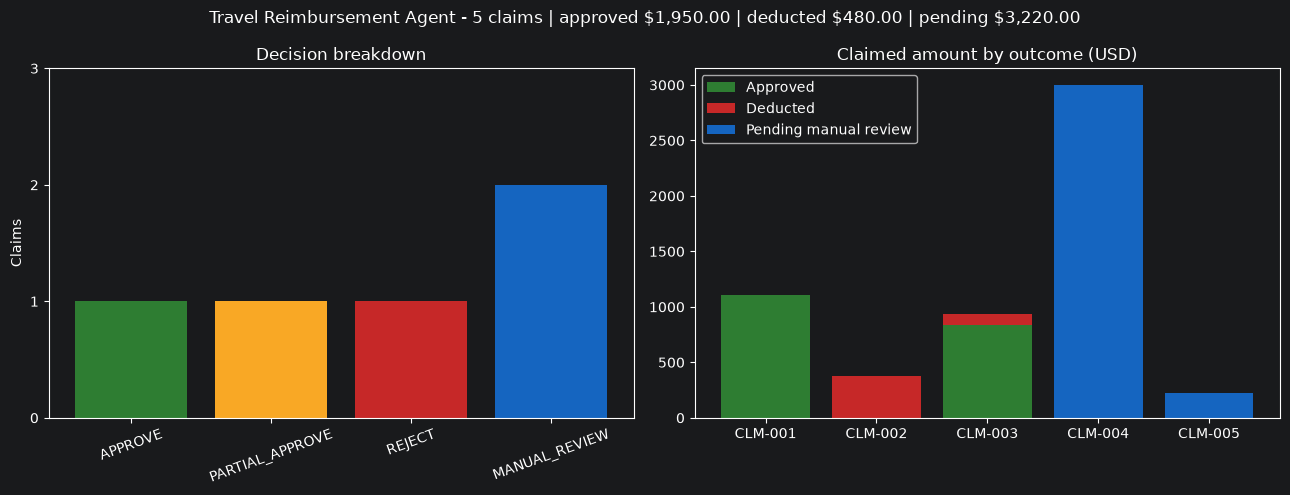

In [11]:
"""Results dashboard: data summary (used by the Streamlit UI) and a static PNG."""
import pandas as pd


COLORS = {"APPROVE": "#2e7d32", "PARTIAL_APPROVE": "#f9a825", "REJECT": "#c62828", "MANUAL_REVIEW": "#1565c0"}


def summarize(results: list[ClaimResult], claims: list[Claim]) -> tuple[pd.DataFrame, pd.Series]:
    totals = {c.claim_id: c.total for c in claims}
    df = pd.DataFrame([{
        "claim_id": r.claim_id, "decision": r.decision, "claimed": totals[r.claim_id],
        "approved": r.approved_amount, "deducted": r.deducted_amount,
        "pending_review": round(totals[r.claim_id] - r.approved_amount - r.deducted_amount, 2),
        "confidence": r.confidence,
    } for r in results])
    counts = df["decision"].value_counts().reindex(DECISIONS, fill_value=0)
    return df, counts


def draw_dashboard(results: list[ClaimResult], claims: list[Claim]):
    import matplotlib.pyplot as plt

    df, counts = summarize(results, claims)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
    a1.bar(counts.index, counts.values, color=[COLORS[d] for d in counts.index])
    a1.set_title("Decision breakdown")
    a1.set_ylabel("Claims")
    a1.set_yticks(range(0, int(counts.max()) + 2))
    a1.tick_params(axis="x", rotation=20)
    bottom = [0.0] * len(df)
    for col, color, label in (("approved", "#2e7d32", "Approved"), ("deducted", "#c62828", "Deducted"), ("pending_review", "#1565c0", "Pending manual review")):
        a2.bar(df["claim_id"], df[col], bottom=bottom, color=color, label=label)
        bottom = [b + v for b, v in zip(bottom, df[col])]
    a2.set_title("Claimed amount by outcome (USD)")
    a2.legend()
    fig.suptitle(f"Travel Reimbursement Agent - {len(df)} claims | approved ${df['approved'].sum():,.2f} | "
                 f"deducted ${df['deducted'].sum():,.2f} | pending ${df['pending_review'].sum():,.2f}", fontsize=12)
    fig.tight_layout()
    return fig


def save_png(results: list[ClaimResult], claims: list[Claim], path) -> None:
    import matplotlib.pyplot as plt

    fig = draw_dashboard(results, claims)
    fig.savefig(path, dpi=130)
    plt.close(fig)


import matplotlib.pyplot as plt
from IPython.display import display

summary_df, decision_counts = summarize(results, claims)
display(summary_df)
fig = draw_dashboard(results, claims)
plt.show()

### Interactive UI
Pick a provided claim, or paste your own claim JSON (object or array) and click **Evaluate**. Uses the same agent as above.

In [12]:
try:
    import ipywidgets as w
    from IPython.display import HTML, clear_output, display

    COLORS_UI = {"APPROVE": "#2e7d32", "PARTIAL_APPROVE": "#f9a825", "REJECT": "#c62828", "MANUAL_REVIEW": "#1565c0"}
    picker = w.Dropdown(options=[c.claim_id for c in claims] + ["Custom JSON"], description="Claim:")
    box = w.Textarea(placeholder='Paste claim JSON here (used when "Custom JSON" is selected)', layout=w.Layout(width="100%", height="140px"))
    btn = w.Button(description="Evaluate", button_style="primary")
    out = w.Output()

    def _show(claim, r):
        color = COLORS_UI[r.decision]
        display(HTML(
            f"<div style='border-left:6px solid {color};padding:8px 14px;margin:8px 0'>"
            f"<b>{r.claim_id}</b> - <span style='color:{color};font-weight:bold'>{r.decision}</span> "
            f"&nbsp; approved <b>${r.approved_amount:,.2f}</b> / deducted <b>${r.deducted_amount:,.2f}</b> "
            f"&nbsp; confidence {r.confidence}<br>{r.explanation}<br>"
            f"<small>policy refs: {', '.join(r.policy_refs)} | missing: {', '.join(r.missing_docs) or 'none'} | tools: {', '.join(r.tools_used)}</small></div>"))
        display(pd.DataFrame([i.model_dump() for i in claim.items]))

    def _on_click(_):
        with out:
            clear_output()
            try:
                todo = parse_json(box.value) if picker.value == "Custom JSON" else [c for c in claims if c.claim_id == picker.value]
                for c in todo:
                    _show(c, agent.evaluate(c))
            except Exception as exc:
                print(f"Could not evaluate: {type(exc).__name__}: {exc}")

    btn.on_click(_on_click)
    display(w.VBox([w.HBox([picker, btn]), box, out]))
except ImportError:
    print("Interactive UI needs ipywidgets:  pip install ipywidgets  (the charts above work without it)")

## Evaluation and tests
A labelled suite of **25 cases**: the 5 provided claims plus 20 edge cases around every policy boundary (30 vs 31 days,
$25.00 vs $25.01, $500 / $2,000 / $2,000.01 totals, unknown categories, mismatched totals, receipt conflicts, ...).
Expected outcomes were written from the policy text, not from the program's output. The same suite runs as
`pytest` in the repository (53 tests, including a mocked OpenAI tool-calling loop).

The cell below runs the deterministic baseline and **asserts every case passes**. It also reports how well the
signal-based confidence lines up with observed accuracy (accuracy, Brier score, accuracy per confidence band).
Set `RUN_LLM_EVAL = True` to also run the OpenAI agent over the suite (makes one API call loop per case).

In [13]:
"""Evaluation harness: run labelled cases through an agent and measure correctness + confidence quality."""
import json
from pathlib import Path

import pandas as pd



def load_eval_cases(path) -> list[dict]:
    return json.loads(Path(path).read_text())


def _evaluate_case(agent, case: dict) -> dict:
    claim, exp = Claim(**case["claim"]), case["expected"]
    r = agent.evaluate(claim)
    decision_ok = r.decision == exp["decision"]
    amounts_ok = abs(r.approved_amount - exp["approved_amount"]) < 0.01 and abs(r.deducted_amount - exp["deducted_amount"]) < 0.01
    refs_ok = set(exp.get("policy_refs_include", [])) <= set(r.policy_refs)
    return {
        "case": case["name"], "expected": exp["decision"], "got": r.decision,
        "approved": r.approved_amount, "deducted": r.deducted_amount, "confidence": r.confidence,
        "decision_ok": decision_ok, "amounts_ok": amounts_ok, "refs_ok": refs_ok,
        "passed": decision_ok and amounts_ok and refs_ok,
    }


def run_evaluation(agent, cases: list[dict], workers: int = 1, progress: bool = False) -> pd.DataFrame:
    """Each case: {name, description, claim, expected: {decision, approved_amount, deducted_amount, policy_refs_include}}.

    workers > 1 evaluates cases in parallel threads (useful for LLM mode); row order is preserved.
    progress=True prints one line per finished case (with seconds taken) so long LLM runs are visibly alive.
    """
    import time
    from concurrent.futures import ThreadPoolExecutor, as_completed

    rows: list = [None] * len(cases)

    def work(i: int):
        t0 = time.time()
        row = _evaluate_case(agent, cases[i])
        row["seconds"] = round(time.time() - t0, 1)
        return i, row

    def report(done: int, row: dict) -> None:
        if progress:
            print(f"  [{done}/{len(cases)}] {row['case']}: {row['got']} ({row['seconds']}s) {'ok' if row['passed'] else 'FAIL (expected ' + row['expected'] + ')'}", flush=True)

    if workers <= 1:
        for n, i in enumerate(range(len(cases)), 1):
            _, rows[i] = work(i)
            report(n, rows[i])
    else:
        with ThreadPoolExecutor(max_workers=workers) as pool:
            for n, fut in enumerate(as_completed([pool.submit(work, i) for i in range(len(cases))]), 1):
                i, row = fut.result()
                rows[i] = row
                report(n, row)
    return pd.DataFrame(rows)


def summarize_evaluation(df: pd.DataFrame) -> dict:
    """Accuracy plus a simple confidence check: Brier score and mean confidence vs observed accuracy."""
    correct = df["passed"].astype(float)
    return {
        "cases": len(df),
        "passed": int(df["passed"].sum()),
        "accuracy": round(float(correct.mean()), 3),
        "mean_confidence": round(float(df["confidence"].mean()), 3),
        "brier_score": round(float(((df["confidence"] - correct) ** 2).mean()), 4),  # 0 = perfect, lower is better
        "manual_review_precision": _precision(df),
    }


def _precision(df: pd.DataFrame) -> float | None:
    routed = df[df["got"] == "MANUAL_REVIEW"]
    return None if routed.empty else round(float((routed["expected"] == "MANUAL_REVIEW").mean()), 3)


def confidence_bands(df: pd.DataFrame) -> pd.DataFrame:
    bands = pd.cut(df["confidence"], [0, 0.7, 0.85, 0.95, 1.0], labels=["<=0.70", "0.70-0.85", "0.85-0.95", ">0.95"])
    out = df.groupby(bands, observed=True).agg(cases=("passed", "size"), accuracy=("passed", "mean"), mean_confidence=("confidence", "mean"))
    return out.round(3)

EVAL_CASES = json.loads(r'''
[
 {
  "name": "CLM-001 (provided)",
  "description": "Attend 2-day industry conference (business)",
  "claim": {
   "claim_id": "CLM-001",
   "employee": "A. Rivera",
   "purpose": "Attend 2-day industry conference (business)",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-12",
   "submitted_date": "2026-06-20",
   "currency": "USD",
   "total_claimed": 1110.0,
   "items": [
    {
     "category": "airfare",
     "description": "Round-trip economy airfare",
     "amount": 420.0,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1,
     "fare_class": "economy"
    },
    {
     "category": "lodging",
     "description": "Hotel, 2 nights @ $180",
     "amount": 360.0,
     "receipt_attached": true,
     "units": 2,
     "attendees": 1
    },
    {
     "category": "meals",
     "description": "Meals, 3 days @ ~$60/day",
     "amount": 180.0,
     "receipt_attached": true,
     "units": 3,
     "attendees": 1
    },
    {
     "category": "conference_fees",
     "description": "Conference registration",
     "amount": 150.0,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "APPROVE",
   "approved_amount": 1110,
   "deducted_amount": 0,
   "policy_refs_include": [
    "POL-APR-02"
   ]
  }
 },
 {
  "name": "CLM-002 (provided)",
  "description": "Weekend hotel stay",
  "claim": {
   "claim_id": "CLM-002",
   "employee": "B. Osei",
   "purpose": "Weekend hotel stay",
   "trip_start": "2026-06-14",
   "trip_end": "2026-06-15",
   "submitted_date": "2026-06-25",
   "currency": "USD",
   "total_claimed": 380.0,
   "items": [
    {
     "category": "spa",
     "description": "Hotel spa package",
     "amount": 300.0,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1
    },
    {
     "category": "minibar",
     "description": "In-room minibar",
     "amount": 80.0,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "REJECT",
   "approved_amount": 0,
   "deducted_amount": 380,
   "policy_refs_include": [
    "POL-CAT-02"
   ]
  }
 },
 {
  "name": "CLM-003 (provided)",
  "description": "Client site visit (business)",
  "claim": {
   "claim_id": "CLM-003",
   "employee": "C. Nakamura",
   "purpose": "Client site visit (business)",
   "trip_start": "2026-06-08",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-06-22",
   "currency": "USD",
   "total_claimed": 940.0,
   "items": [
    {
     "category": "airfare",
     "description": "Round-trip economy airfare",
     "amount": 300.0,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1,
     "fare_class": "economy"
    },
    {
     "category": "lodging",
     "description": "Hotel, 2 nights @ $250",
     "amount": 500.0,
     "receipt_attached": true,
     "units": 2,
     "attendees": 1
    },
    {
     "category": "meals",
     "description": "Meals, 2 days @ $70/day",
     "amount": 140.0,
     "receipt_attached": true,
     "units": 2,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "PARTIAL_APPROVE",
   "approved_amount": 840,
   "deducted_amount": 100,
   "policy_refs_include": [
    "POL-PD-02",
    "POL-APR-02"
   ]
  }
 },
 {
  "name": "CLM-004 (provided)",
  "description": "International vendor negotiation (business)",
  "claim": {
   "claim_id": "CLM-004",
   "employee": "D. Fischer",
   "purpose": "International vendor negotiation (business)",
   "trip_start": "2026-06-16",
   "trip_end": "2026-06-18",
   "submitted_date": "2026-06-28",
   "currency": "USD",
   "total_claimed": 3000.0,
   "items": [
    {
     "category": "airfare",
     "description": "Business-class international airfare",
     "amount": 2400.0,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1,
     "fare_class": "business"
    },
    {
     "category": "lodging",
     "description": "Hotel, 3 nights",
     "amount": 600.0,
     "receipt_attached": false,
     "units": 3,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "MANUAL_REVIEW",
   "approved_amount": 0,
   "deducted_amount": 0,
   "policy_refs_include": [
    "POL-AIR-01",
    "POL-RCT-02",
    "POL-APR-03"
   ]
  }
 },
 {
  "name": "CLM-005 (provided)",
  "description": "Client dinner / business development",
  "claim": {
   "claim_id": "CLM-005",
   "employee": "E. Haddad",
   "purpose": "Client dinner / business development",
   "trip_start": "2026-06-11",
   "trip_end": "2026-06-11",
   "submitted_date": "2026-06-24",
   "currency": "USD",
   "total_claimed": 220.0,
   "items": [
    {
     "category": "meals",
     "description": "Client dinner for 4 (business development)",
     "amount": 220.0,
     "receipt_attached": false,
     "units": 1,
     "attendees": 4
    }
   ]
  },
  "expected": {
   "decision": "MANUAL_REVIEW",
   "approved_amount": 0,
   "deducted_amount": 0,
   "policy_refs_include": [
    "POL-RCT-02"
   ]
  }
 },
 {
  "name": "meal over daily cap",
  "description": "Dinner $100 vs $75/day cap -> deduct $25",
  "claim": {
   "claim_id": "EDGE-01",
   "employee": "T. Tester",
   "purpose": "Evaluation case",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-06-12",
   "currency": "USD",
   "total_claimed": 100,
   "items": [
    {
     "category": "meals",
     "description": "Dinner",
     "amount": 100,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "PARTIAL_APPROVE",
   "approved_amount": 75,
   "deducted_amount": 25,
   "policy_refs_include": [
    "POL-PD-01"
   ]
  }
 },
 {
  "name": "late claim (52 days)",
  "description": "Submitted long after the 30-day window",
  "claim": {
   "claim_id": "EDGE-02",
   "employee": "T. Tester",
   "purpose": "Evaluation case",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-08-01",
   "currency": "USD",
   "total_claimed": 40,
   "items": [
    {
     "category": "ground_transport",
     "description": "Taxi",
     "amount": 40,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "MANUAL_REVIEW",
   "approved_amount": 0,
   "deducted_amount": 0,
   "policy_refs_include": [
    "POL-TIME-01"
   ]
  }
 },
 {
  "name": "exactly 30 days is on time",
  "description": "Boundary: 30 days is within the window",
  "claim": {
   "claim_id": "EDGE-03",
   "employee": "T. Tester",
   "purpose": "Evaluation case",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-07-10",
   "currency": "USD",
   "total_claimed": 40,
   "items": [
    {
     "category": "ground_transport",
     "description": "Taxi",
     "amount": 40,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "APPROVE",
   "approved_amount": 40,
   "deducted_amount": 0,
   "policy_refs_include": [
    "POL-APR-01"
   ]
  }
 },
 {
  "name": "31 days is late",
  "description": "Boundary: 31 days is outside the window",
  "claim": {
   "claim_id": "EDGE-04",
   "employee": "T. Tester",
   "purpose": "Evaluation case",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-07-11",
   "currency": "USD",
   "total_claimed": 40,
   "items": [
    {
     "category": "ground_transport",
     "description": "Taxi",
     "amount": 40,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "MANUAL_REVIEW",
   "approved_amount": 0,
   "deducted_amount": 0,
   "policy_refs_include": [
    "POL-TIME-01"
   ]
  }
 },
 {
  "name": "unknown category",
  "description": "Category not covered by the policy",
  "claim": {
   "claim_id": "EDGE-05",
   "employee": "T. Tester",
   "purpose": "Evaluation case",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-06-12",
   "currency": "USD",
   "total_claimed": 120,
   "items": [
    {
     "category": "visa_fee",
     "description": "Visa fee",
     "amount": 120,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "MANUAL_REVIEW",
   "approved_amount": 0,
   "deducted_amount": 0,
   "policy_refs_include": [
    "POL-CAT-01"
   ]
  }
 },
 {
  "name": "stated total mismatch",
  "description": "Form total differs from sum of items",
  "claim": {
   "claim_id": "EDGE-06",
   "employee": "T. Tester",
   "purpose": "Evaluation case",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-06-12",
   "currency": "USD",
   "total_claimed": 150.0,
   "items": [
    {
     "category": "ground_transport",
     "description": "Taxi",
     "amount": 100,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "MANUAL_REVIEW",
   "approved_amount": 0,
   "deducted_amount": 0,
   "policy_refs_include": []
  }
 },
 {
  "name": "receipt not needed at exactly $25",
  "description": "Boundary: receipt only required above $25",
  "claim": {
   "claim_id": "EDGE-07",
   "employee": "T. Tester",
   "purpose": "Evaluation case",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-06-12",
   "currency": "USD",
   "total_claimed": 25.0,
   "items": [
    {
     "category": "meals",
     "description": "Snack",
     "amount": 25.0,
     "receipt_attached": false,
     "units": 1,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "APPROVE",
   "approved_amount": 25,
   "deducted_amount": 0,
   "policy_refs_include": [
    "POL-APR-01"
   ]
  }
 },
 {
  "name": "receipt needed above $25",
  "description": "Boundary: $25.01 without receipt",
  "claim": {
   "claim_id": "EDGE-08",
   "employee": "T. Tester",
   "purpose": "Evaluation case",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-06-12",
   "currency": "USD",
   "total_claimed": 25.01,
   "items": [
    {
     "category": "meals",
     "description": "Lunch",
     "amount": 25.01,
     "receipt_attached": false,
     "units": 1,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "MANUAL_REVIEW",
   "approved_amount": 0,
   "deducted_amount": 0,
   "policy_refs_include": [
    "POL-RCT-02"
   ]
  }
 },
 {
  "name": "tier boundary $500",
  "description": "Total exactly $500 is auto-approve tier",
  "claim": {
   "claim_id": "EDGE-09",
   "employee": "T. Tester",
   "purpose": "Evaluation case",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-06-12",
   "currency": "USD",
   "total_claimed": 500.0,
   "items": [
    {
     "category": "airfare",
     "description": "Economy flight",
     "amount": 500.0,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1,
     "fare_class": "economy"
    }
   ]
  },
  "expected": {
   "decision": "APPROVE",
   "approved_amount": 500,
   "deducted_amount": 0,
   "policy_refs_include": [
    "POL-APR-01"
   ]
  }
 },
 {
  "name": "tier boundary $2,000",
  "description": "Total exactly $2,000 is manager tier",
  "claim": {
   "claim_id": "EDGE-10",
   "employee": "T. Tester",
   "purpose": "Evaluation case",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-06-12",
   "currency": "USD",
   "total_claimed": 2000.0,
   "items": [
    {
     "category": "airfare",
     "description": "Economy flight",
     "amount": 2000.0,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1,
     "fare_class": "economy"
    }
   ]
  },
  "expected": {
   "decision": "APPROVE",
   "approved_amount": 2000,
   "deducted_amount": 0,
   "policy_refs_include": [
    "POL-APR-02"
   ]
  }
 },
 {
  "name": "just above $2,000",
  "description": "$2,000.01 exceeds agent authority",
  "claim": {
   "claim_id": "EDGE-11",
   "employee": "T. Tester",
   "purpose": "Evaluation case",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-06-12",
   "currency": "USD",
   "total_claimed": 2000.01,
   "items": [
    {
     "category": "airfare",
     "description": "Economy flight",
     "amount": 2000.01,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1,
     "fare_class": "economy"
    }
   ]
  },
  "expected": {
   "decision": "MANUAL_REVIEW",
   "approved_amount": 0,
   "deducted_amount": 0,
   "policy_refs_include": [
    "POL-APR-03"
   ]
  }
 },
 {
  "name": "eligible + ineligible mix",
  "description": "Valid airfare plus a spa charge",
  "claim": {
   "claim_id": "EDGE-12",
   "employee": "T. Tester",
   "purpose": "Evaluation case",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-06-12",
   "currency": "USD",
   "total_claimed": 400,
   "items": [
    {
     "category": "airfare",
     "description": "Economy flight",
     "amount": 300,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1,
     "fare_class": "economy"
    },
    {
     "category": "spa",
     "description": "Spa",
     "amount": 100,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "PARTIAL_APPROVE",
   "approved_amount": 300,
   "deducted_amount": 100,
   "policy_refs_include": [
    "POL-CAT-02"
   ]
  }
 },
 {
  "name": "ground transport cap",
  "description": "$120 over 2 days vs $50/day cap",
  "claim": {
   "claim_id": "EDGE-13",
   "employee": "T. Tester",
   "purpose": "Evaluation case",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-06-12",
   "currency": "USD",
   "total_claimed": 120,
   "items": [
    {
     "category": "ground_transport",
     "description": "Taxis",
     "amount": 120,
     "receipt_attached": true,
     "units": 2,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "PARTIAL_APPROVE",
   "approved_amount": 100,
   "deducted_amount": 20,
   "policy_refs_include": [
    "POL-PD-03"
   ]
  }
 },
 {
  "name": "airfare class not stated",
  "description": "Cannot confirm economy-only rule",
  "claim": {
   "claim_id": "EDGE-14",
   "employee": "T. Tester",
   "purpose": "Evaluation case",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-06-12",
   "currency": "USD",
   "total_claimed": 400,
   "items": [
    {
     "category": "airfare",
     "description": "Flight to Chicago",
     "amount": 400,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "MANUAL_REVIEW",
   "approved_amount": 0,
   "deducted_amount": 0,
   "policy_refs_include": [
    "POL-AIR-01"
   ]
  }
 },
 {
  "name": "first-class airfare",
  "description": "Policy exception, not auto-deducted",
  "claim": {
   "claim_id": "EDGE-15",
   "employee": "T. Tester",
   "purpose": "Evaluation case",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-06-12",
   "currency": "USD",
   "total_claimed": 900,
   "items": [
    {
     "category": "airfare",
     "description": "First class flight",
     "amount": 900,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1,
     "fare_class": "first"
    }
   ]
  },
  "expected": {
   "decision": "MANUAL_REVIEW",
   "approved_amount": 0,
   "deducted_amount": 0,
   "policy_refs_include": [
    "POL-AIR-01"
   ]
  }
 },
 {
  "name": "small lodging, no receipt",
  "description": "Lodging always needs a receipt",
  "claim": {
   "claim_id": "EDGE-16",
   "employee": "T. Tester",
   "purpose": "Evaluation case",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-06-12",
   "currency": "USD",
   "total_claimed": 20,
   "items": [
    {
     "category": "lodging",
     "description": "Hotel",
     "amount": 20,
     "receipt_attached": false,
     "units": 1,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "MANUAL_REVIEW",
   "approved_amount": 0,
   "deducted_amount": 0,
   "policy_refs_include": [
    "POL-RCT-02"
   ]
  }
 },
 {
  "name": "receipt amount mismatch",
  "description": "Receipt on file says $420, claim says $430",
  "claim": {
   "claim_id": "CLM-001",
   "employee": "A. Rivera",
   "purpose": "Attend 2-day industry conference (business)",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-12",
   "submitted_date": "2026-06-20",
   "currency": "USD",
   "total_claimed": 1120.0,
   "items": [
    {
     "category": "airfare",
     "description": "Round-trip economy airfare",
     "amount": 430.0,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1,
     "fare_class": "economy"
    },
    {
     "category": "lodging",
     "description": "Hotel, 2 nights @ $180",
     "amount": 360.0,
     "receipt_attached": true,
     "units": 2,
     "attendees": 1
    },
    {
     "category": "meals",
     "description": "Meals, 3 days",
     "amount": 180.0,
     "receipt_attached": true,
     "units": 3,
     "attendees": 1
    },
    {
     "category": "conference_fees",
     "description": "Conference registration",
     "amount": 150.0,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "MANUAL_REVIEW",
   "approved_amount": 0,
   "deducted_amount": 0,
   "policy_refs_include": []
  }
 },
 {
  "name": "submitted before trip",
  "description": "Impossible date ordering",
  "claim": {
   "claim_id": "EDGE-18",
   "employee": "T. Tester",
   "purpose": "Evaluation case",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-06-01",
   "currency": "USD",
   "total_claimed": 40,
   "items": [
    {
     "category": "ground_transport",
     "description": "Taxi",
     "amount": 40,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "MANUAL_REVIEW",
   "approved_amount": 0,
   "deducted_amount": 0,
   "policy_refs_include": []
  }
 },
 {
  "name": "alcohol only",
  "description": "Ineligible: nothing reimbursable",
  "claim": {
   "claim_id": "EDGE-19",
   "employee": "T. Tester",
   "purpose": "Evaluation case",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-06-12",
   "currency": "USD",
   "total_claimed": 60,
   "items": [
    {
     "category": "alcohol",
     "description": "Bar tab",
     "amount": 60,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "REJECT",
   "approved_amount": 0,
   "deducted_amount": 60,
   "policy_refs_include": [
    "POL-CAT-02"
   ]
  }
 },
 {
  "name": "category alias (taxi)",
  "description": "'Taxi' maps to ground_transport",
  "claim": {
   "claim_id": "EDGE-20",
   "employee": "T. Tester",
   "purpose": "Evaluation case",
   "trip_start": "2026-06-10",
   "trip_end": "2026-06-10",
   "submitted_date": "2026-06-12",
   "currency": "USD",
   "total_claimed": 30,
   "items": [
    {
     "category": "Taxi",
     "description": "Airport taxi",
     "amount": 30,
     "receipt_attached": true,
     "units": 1,
     "attendees": 1
    }
   ]
  },
  "expected": {
   "decision": "APPROVE",
   "approved_amount": 30,
   "deducted_amount": 0,
   "policy_refs_include": [
    "POL-PD-03"
   ]
  }
 }
]
''')

In [18]:
RUN_LLM_EVAL = True  # True -> also evaluate the OpenAI agent (needs OPENAI_API_KEY)

baseline = TravelReimbursementAgent(mode="llm")
eval_df = run_evaluation(baseline, EVAL_CASES)
print(eval_df[["case", "expected", "got", "approved", "deducted", "confidence", "passed"]].to_string(index=False))
print("\nSummary :", summarize_evaluation(eval_df))
print("\nConfidence vs observed accuracy:\n", confidence_bands(eval_df))
assert eval_df["passed"].all(), "evaluation failures: " + ", ".join(eval_df.loc[~eval_df["passed"], "case"])
print(f"\nAll {len(eval_df)} labelled cases passed (deterministic baseline).")

if RUN_LLM_EVAL and agent.mode == "llm":
    llm_df = run_evaluation(agent, EVAL_CASES)
    print("\nOpenAI agent:", summarize_evaluation(llm_df))
    print(llm_df.loc[~llm_df["passed"], ["case", "expected", "got"]].to_string(index=False) or "no disagreements")

                             case        expected             got  approved  deducted  confidence  passed
               CLM-001 (provided)         APPROVE         APPROVE    1110.0       0.0        0.97    True
               CLM-002 (provided)          REJECT          REJECT       0.0     380.0        0.98    True
               CLM-003 (provided) PARTIAL_APPROVE PARTIAL_APPROVE     840.0     100.0        0.90    True
               CLM-004 (provided)   MANUAL_REVIEW   MANUAL_REVIEW       0.0       0.0        0.70    True
               CLM-005 (provided)   MANUAL_REVIEW   MANUAL_REVIEW       0.0       0.0        0.70    True
              meal over daily cap PARTIAL_APPROVE PARTIAL_APPROVE      75.0      25.0        0.90    True
             late claim (52 days)   MANUAL_REVIEW   MANUAL_REVIEW       0.0       0.0        0.70    True
       exactly 30 days is on time         APPROVE         APPROVE      40.0       0.0        0.97    True
                  31 days is late   MANUAL_REV

## Design Notes & Reasoning

### Approach in one paragraph
The policy is encoded as data (policy rules, a limit table and an approval matrix) and exposed through seven small
deterministic tools. In LLM mode, an OpenAI model (function calling) decides which tools to call, reads the results,
and submits a decision and explanation. In offline mode, a fixed planner calls the same tools. In both modes the
numbers (caps, totals, tiers) come from tools, never from the model, and the final decision is cross-checked by an
independent policy engine and an output validator before it is returned.

### Key design choices and trade-offs
| Choice | Why | Trade-off |
|---|---|---|
| Deterministic tools do all arithmetic and rule checks | LLMs are unreliable at money math; results are auditable and repeatable | Policy changes mean editing data/code, not just a prompt |
| LLM (OpenAI function calling) chooses tools, combines results, writes the explanation | Demonstrates agentic reasoning; explanations read naturally | Slower and costs API calls vs. pure rules |
| Verifier: LLM decision differs from engine decision -> `MANUAL_REVIEW` | A wrong auto-approval is the costly failure; humans are the safe fallback | May over-route if the model is conservative |
| Offline planner using the same tools | Runs with no key/network; reproducible demos and tests | Not "agentic" - it is the control baseline |
| Keyword retrieval over 12 rules instead of a vector DB | At this size retrieval is trivial; keeps setup light | Would not scale to a long policy document |
| Tools are bound to one claim (`ToolBox`) | The model cannot mix data between claims; tools take no claim id | - |
| Pydantic output model + validator | Guarantees the exact output contract and internal consistency | - |
| Fail fast on fatal API errors, then continue offline | One bad key/endpoint should not stall or crash the batch | Rest of the run is not LLM-driven |

### Why certain cases go to Manual Review
* **CLM-004** - Three independent triggers. Business-class fare is an exception that must not be auto-deducted
  because a pre-approval may exist (POL-AIR-01). The lodging receipt is missing, so the item is not silently
  rejected (POL-RCT-02). The reimbursable total ($3,000) exceeds the agent's $2,000 authority (POL-APR-03).
* **CLM-005** - The $220 dinner has no receipt (POL-RCT-01/02). Also, the $75/day cap does not say how it applies to a
  client dinner for four, so the agent flags an ambiguity instead of guessing it should deduct $145.
* General rule: missing required receipts, policy exceptions, unknown categories, late claims (POL-TIME-01),
  conflicting data, and totals above $2,000 always route to Manual Review.

### Evaluation, testing and confidence
* **Labelled evaluation suite** (25 cases): the 5 provided claims plus 20 edge cases that probe every boundary -
  exactly 30 vs 31 days, receipt at $25.00 vs $25.01, totals of $500 / $2,000 / $2,000.01, unknown categories,
  mismatched totals, receipt-amount conflicts, category aliases, ground-transport caps and more. Expected outcomes
  were written from the policy text, not from the program's output.
* **Automated tests** (`pytest`, 53 tests): each tool, the decision engine on all 25 cases, the exact output
  contract, validator guardrails, CSV vs JSON intake, and the OpenAI tool-calling loop with a mocked client
  (agreement, disagreement, garbage confidence, no submission, API failure). The notebook runs the same suite.
* **Confidence** is a transparent function of explicit signals rather than a fixed number per decision: a base by
  decision type, minus a penalty for each ambiguity signal (conflicting data, unknown category, group meal,
  unspecified airfare class), minus a small one when an auto-approval is within 5% of a tier boundary. The
  evaluation reports accuracy, mean confidence, Brier score and accuracy per confidence band. With 25 cases this
  is a sanity check, not true calibration - see "Known gaps".

### Assumptions
1. Per-diem caps scale by `units` on each line item (days for meals/ground transport, nights for lodging); `units`
   is part of the claim data (e.g. "2 nights" -> `units: 2`).
2. Approval tiers are evaluated on the total reimbursable amount after per-diem deductions, and include items that
   are pending review (so CLM-004's $3,000 hits POL-APR-03).
3. The "expense date" is the item's `expense_date` if given, else the trip start date (the conservative choice).
4. For `MANUAL_REVIEW`, no amount is finalised: `approved_amount = deducted_amount = 0`; the indicative amounts
   appear in the explanation. For other decisions, `approved + deducted = total claimed`.
5. A claim with eligible items plus ineligible items (and nothing else wrong) is `PARTIAL_APPROVE`.
6. Group meals (`attendees > 1`) are treated as ambiguous because the policy is silent on them.
7. Business purpose is taken from the claim's `purpose` text; it is not independently verified.
8. All data is mock: no real employee or company data is used.

### Known gaps / limitations
* Receipts are mock metadata; there is no OCR or image/PDF parsing.
* No duplicate-claim detection across claims, no currency conversion (USD only).
* Confidence is signal-based and checked on 25 labelled cases; real calibration needs a larger labelled set,
  ideally with human reviewer outcomes. The labelled cases are also written by the author, so agreement with the
  engine is partly self-consistency; the five provided claims are the independent anchor.
* Real-model behaviour is only exercised when an `OPENAI_API_KEY` is set. The committed notebook outputs and the
  automated tests use offline mode and a mocked client respectively.
* Single-claim, in-memory processing; no persistence or authentication.

### What I would improve next
* Parse real receipt PDFs/images and reconcile vendor/date/amount with line items.
* Duplicate and split-claim detection across a batch and history.
* Calibrate confidence on a larger labelled set with human reviewer outcomes.
* Run the evaluation suite against several OpenAI models and report agreement with the policy engine.
* Reviewer workflow: request-missing-document messages, approver routing by tier, and an audit trail.

## Final results
JSON array with one object per provided claim (exact fields required by the assignment).

In [15]:
FIELDS = ["claim_id", "decision", "approved_amount", "deducted_amount", "missing_docs", "policy_refs", "confidence", "explanation", "tools_used"]
final_output = [r.model_dump() for r in results]
assert len(final_output) == 5 and all(list(o) == FIELDS for o in final_output), "output does not match the required contract"
print(json.dumps(final_output, indent=2))

[
  {
    "claim_id": "CLM-001",
    "decision": "APPROVE",
    "approved_amount": 1110.0,
    "deducted_amount": 0.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-AIR-01",
      "POL-APR-02",
      "POL-CAT-01",
      "POL-PD-01",
      "POL-PD-02",
      "POL-RCT-01"
    ],
    "confidence": 0.97,
    "explanation": "The claim is fully eligible with all required receipts present. The total amount of $1110.00 is within the approvable tier (POL-APR-02). All items are within per-diem limits, with no excess amounts. Therefore, I recommend approving the full claim.",
    "tools_used": [
      "lookup_policy",
      "check_claim_consistency",
      "check_category_eligibility",
      "check_receipts",
      "check_per_diem_limits",
      "check_timeliness",
      "check_approval_threshold",
      "validate_output"
    ]
  },
  {
    "claim_id": "CLM-002",
    "decision": "REJECT",
    "approved_amount": 0.0,
    "deducted_amount": 380.0,
    "missing_docs": [],
    "policy_refs"